## Гауссовская инверсия DBM


In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

from tqdm.auto import tqdm


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


current_directory = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        directory
        for directory in (
            current_directory,
            *current_directory.parents,
        )
        if (directory / "src").is_dir()
        and (
            directory / "data" / "ml_dataset" / "dataset_inverse.csv"
        ).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден корень проекта с папкой src и dataset_inverse.csv"
    )

DATA_DIR = PROJECT_ROOT / "data" / "ml_dataset"
DATA_FILE = DATA_DIR / "dataset_inverse.csv"

CNN_CHECKPOINT_FILE = (
    PROJECT_ROOT / "results" / "cnn_inverse" / "best_cnn.pt"
)

RESULTS_DIR = PROJECT_ROOT / "results" / "probabilistic_inverse"

assert CNN_CHECKPOINT_FILE.is_file(), (
    f"Не найдены веса CNN: {CNN_CHECKPOINT_FILE}"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Устройство:", DEVICE)
print("Корень проекта:", PROJECT_ROOT)
print("Датасет:", DATA_FILE)
print("Веса CNN:", CNN_CHECKPOINT_FILE)
print("Результаты:", RESULTS_DIR)

PyTorch: 2.14.1+cu130
Устройство: cpu
Корень проекта: /home/artur/PycharmProjects/Mathprac
Датасет: /home/artur/PycharmProjects/Mathprac/data/ml_dataset/dataset_inverse.csv
Веса CNN: /home/artur/PycharmProjects/Mathprac/results/cnn_inverse/best_cnn.pt
Результаты: /home/artur/PycharmProjects/Mathprac/results/probabilistic_inverse


In [2]:
cnn_checkpoint = torch.load(
    CNN_CHECKPOINT_FILE,
    map_location="cpu",
    weights_only=False,
)

required_checkpoint_keys = {
    "model_state_dict",
    "target_columns",
    "target_mean",
    "target_std",
    "epoch",
    "validation_loss",
}

missing_keys = required_checkpoint_keys - set(cnn_checkpoint)

assert not missing_keys, (
    f"В checkpoint отсутствуют поля: {sorted(missing_keys)}"
)

TARGET_COLUMNS = list(cnn_checkpoint["target_columns"])

assert len(TARGET_COLUMNS) == 4
assert set(TARGET_COLUMNS) == {
    "eta",
    "mean_breakdown_field",
    "correlation_length",
    "weibull_shape",
}

target_mean = pd.Series(
    cnn_checkpoint["target_mean"],
    dtype=np.float64,
).reindex(TARGET_COLUMNS)

target_std = pd.Series(
    cnn_checkpoint["target_std"],
    dtype=np.float64,
).reindex(TARGET_COLUMNS)

assert np.isfinite(target_mean.to_numpy()).all()
assert np.isfinite(target_std.to_numpy()).all()
assert (target_std > 0).all()

normalization_table = pd.DataFrame(
    {
        "target": TARGET_COLUMNS,
        "train_mean": target_mean.to_numpy(),
        "train_std": target_std.to_numpy(),
    }
)

print("Лучшая эпоха CNN:", cnn_checkpoint["epoch"])
print("Validation loss CNN:", cnn_checkpoint["validation_loss"])

display(normalization_table)

Лучшая эпоха CNN: 21
Validation loss CNN: 0.2656547117973967


,target,train_mean,train_std
0,eta,1.743324,0.734644
1,mean_breakdown_field,2.957729,0.167796
2,correlation_length,6.107927,4.424977
3,weibull_shape,7.503295,3.822293


In [3]:
from sklearn.model_selection import GroupShuffleSplit


dataset = pd.read_csv(
    DATA_FILE,
    dtype={
        "run_id": str,
        "disorder_seed": "uint64",
        "random_seed": "uint64",
    },
)

required_columns = {
    "run_id",
    "point_id",
    "split",
    "image_path",
    *TARGET_COLUMNS,
}

missing_columns = required_columns - set(dataset.columns)
assert not missing_columns, f"Нет столбцов: {sorted(missing_columns)}"

assert dataset["run_id"].notna().all()
assert dataset["run_id"].is_unique
assert dataset["point_id"].notna().all()
assert dataset["image_path"].notna().all()
assert set(dataset["split"]) == {"train", "test"}

assert np.isfinite(
    dataset[TARGET_COLUMNS].to_numpy(dtype=np.float64)
).all()

train_pool = dataset.loc[dataset["split"] == "train"].copy()
test_data = dataset.loc[dataset["split"] == "test"].copy()

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED,
)

train_indices, validation_indices = next(
    group_split.split(
        train_pool,
        groups=train_pool["point_id"],
    )
)

train_data = train_pool.iloc[train_indices].reset_index(drop=True)
validation_data = (
    train_pool.iloc[validation_indices].reset_index(drop=True)
)
test_data = test_data.reset_index(drop=True)

for first, second in [
    (train_data, validation_data),
    (train_data, test_data),
    (validation_data, test_data),
]:
    assert set(first["point_id"]).isdisjoint(
        set(second["point_id"])
    ), "Обнаружено пересечение групп между частями датасета"

np.testing.assert_allclose(
    train_data[TARGET_COLUMNS].mean().to_numpy(),
    target_mean.to_numpy(),
    rtol=1e-6,
    atol=1e-6,
    err_msg="Средние train не совпадают со статистиками checkpoint",
)

np.testing.assert_allclose(
    train_data[TARGET_COLUMNS].std(ddof=0).to_numpy(),
    target_std.to_numpy(),
    rtol=1e-6,
    atol=1e-6,
    err_msg="Стандартные отклонения train не совпадают с checkpoint",
)

print("Train:", len(train_data))
print("Validation:", len(validation_data))
print("Test:", len(test_data))

Train: 6560
Validation: 1706
Test: 1933


In [5]:
class GaussianHead(nn.Module):
    def __init__(
        self,
        embedding_size=128,
        hidden_size=64,
        number_of_targets=4,
        variance_floor=1e-6,
    ):
        super().__init__()

        self.variance_floor = variance_floor

        self.hidden = nn.Sequential(
            nn.Linear(embedding_size, hidden_size),
            nn.ReLU(),
        )

        self.mean_layer = nn.Linear(
            hidden_size,
            number_of_targets,
        )

        self.variance_layer = nn.Linear(
            hidden_size,
            number_of_targets,
        )

    def forward(self, embedding):
        hidden = self.hidden(embedding)

        mean = self.mean_layer(hidden)
        raw_variance = self.variance_layer(hidden)

        variance = F.softplus(raw_variance) + self.variance_floor

        return mean, variance


gaussian_head = GaussianHead(
    number_of_targets=len(TARGET_COLUMNS),
).to(DEVICE)

elementwise_gaussian_nll = nn.GaussianNLLLoss(
    full=True,
    eps=1e-6,
    reduction="none",
)


def gaussian_nll_loss(mean, variance, targets):
    losses = elementwise_gaussian_nll(
        input=mean,
        target=targets,
        var=variance,
    )

    return losses.sum(dim=1).mean()


print(gaussian_head)

GaussianHead(
  (hidden): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
  )
  (mean_layer): Linear(in_features=64, out_features=4, bias=True)
  (variance_layer): Linear(in_features=64, out_features=4, bias=True)
)


In [7]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.cnn_inverse import DBMResidualCNN


frozen_cnn = DBMResidualCNN(
    number_of_targets=len(TARGET_COLUMNS),
)

frozen_cnn.load_state_dict(
    cnn_checkpoint["model_state_dict"],
    strict=True,
)

frozen_cnn = frozen_cnn.to(DEVICE)
frozen_cnn.requires_grad_(False)
frozen_cnn.eval()

gaussian_head = GaussianHead(
    number_of_targets=len(TARGET_COLUMNS),
).to(DEVICE)


sample_file = DATA_DIR / train_data.iloc[0]["image_path"]

with np.load(sample_file, allow_pickle=False) as saved:
    sample_mask_array = saved["channel"].astype(np.float32)

assert sample_mask_array.shape == (128, 128)

sample_mask = (
    torch.from_numpy(sample_mask_array)
    .unsqueeze(0)
    .unsqueeze(0)
    .to(DEVICE)
)

with torch.no_grad():
    sample_embedding = frozen_cnn.encode(sample_mask)

    sample_mean, sample_variance = gaussian_head(
        sample_embedding
    )

print("Маска:", sample_mask.shape)
print("Признаки CNN:", sample_embedding.shape)
print("Средние:", sample_mean.shape)
print("Дисперсии:", sample_variance.shape)
print("Пример дисперсий:", sample_variance[0].cpu())

print(
    "Обучаемых параметров CNN:",
    sum(
        parameter.numel()
        for parameter in frozen_cnn.parameters()
        if parameter.requires_grad
    ),
)

Маска: torch.Size([1, 1, 128, 128])
Признаки CNN: torch.Size([1, 128])
Средние: torch.Size([1, 4])
Дисперсии: torch.Size([1, 4])
Пример дисперсий: tensor([0.6201, 0.6469, 0.6849, 0.7498])
Обучаемых параметров CNN: 0


In [8]:
class DBMMaskDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True).copy()

        normalized_targets = (
            (self.frame[TARGET_COLUMNS] - target_mean)
            / target_std
        ).to_numpy(dtype=np.float32)

        self.targets = torch.from_numpy(normalized_targets)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        image_file = DATA_DIR / self.frame.iloc[index]["image_path"]

        with np.load(image_file, allow_pickle=False) as saved:
            mask_array = saved["channel"].astype(np.float32)

        assert mask_array.shape == (128, 128)

        mask = torch.from_numpy(mask_array).unsqueeze(0)

        return mask, self.targets[index]


def extract_embeddings(frame, description):
    mask_dataset = DBMMaskDataset(frame)

    mask_loader = DataLoader(
        mask_dataset,
        batch_size=64,
        shuffle=False,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
    )

    frozen_cnn.eval()

    embedding_batches = []
    target_batches = []

    with torch.no_grad():
        for masks, targets in tqdm(
            mask_loader,
            desc=description,
            unit="batch",
            colour="green",
        ):
            masks = masks.to(DEVICE)

            embeddings = frozen_cnn.encode(masks)

            embedding_batches.append(embeddings.cpu())
            target_batches.append(targets)

    embeddings = torch.cat(embedding_batches, dim=0)
    targets = torch.cat(target_batches, dim=0)

    assert embeddings.shape == (len(frame), 128)
    assert targets.shape == (len(frame), len(TARGET_COLUMNS))
    assert torch.isfinite(embeddings).all()
    assert torch.isfinite(targets).all()

    return embeddings, targets


train_embeddings, train_targets = extract_embeddings(
    train_data,
    "Признаки train",
)

validation_embeddings, validation_targets = extract_embeddings(
    validation_data,
    "Признаки validation",
)

test_embeddings, test_targets = extract_embeddings(
    test_data,
    "Признаки test",
)

print("Train:", train_embeddings.shape, train_targets.shape)
print(
    "Validation:",
    validation_embeddings.shape,
    validation_targets.shape,
)
print("Test:", test_embeddings.shape, test_targets.shape)

Признаки train:   0%|          | 0/103 [00:00<?, ?batch/s]

Признаки validation:   0%|          | 0/27 [00:00<?, ?batch/s]

Признаки test:   0%|          | 0/31 [00:00<?, ?batch/s]

Train: torch.Size([6560, 128]) torch.Size([6560, 4])
Validation: torch.Size([1706, 128]) torch.Size([1706, 4])
Test: torch.Size([1933, 128]) torch.Size([1933, 4])


In [9]:
from torch.utils.data import TensorDataset


BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

train_embedding_dataset = TensorDataset(
    train_embeddings,
    train_targets,
)

validation_embedding_dataset = TensorDataset(
    validation_embeddings,
    validation_targets,
)

test_embedding_dataset = TensorDataset(
    test_embeddings,
    test_targets,
)

shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_embedding_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=shuffle_generator,
)

validation_loader = DataLoader(
    validation_embedding_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_embedding_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

optimizer = torch.optim.AdamW(
    gaussian_head.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5,
    threshold=1e-4,
    threshold_mode="abs",
    min_lr=1e-6,
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

print(
    "Обучаемых параметров головы:",
    sum(
        parameter.numel()
        for parameter in gaussian_head.parameters()
        if parameter.requires_grad
    ),
)

Train batches: 52
Validation batches: 14
Test batches: 16
Обучаемых параметров головы: 8776


In [10]:
def run_gaussian_epoch(
    head,
    loader,
    optimizer=None,
    description="Epoch",
):
    is_training = optimizer is not None
    head.train(is_training)

    total_loss = 0.0
    total_examples = 0

    with tqdm(
        loader,
        desc=description,
        unit="batch",
        colour="green",
        leave=False,
    ) as progress:
        with torch.set_grad_enabled(is_training):
            for embeddings, targets in progress:
                embeddings = embeddings.to(DEVICE)
                targets = targets.to(DEVICE)

                if is_training:
                    optimizer.zero_grad(set_to_none=True)

                mean, variance = head(embeddings)

                loss = gaussian_nll_loss(
                    mean,
                    variance,
                    targets,
                )

                if not torch.isfinite(loss).item():
                    raise RuntimeError(
                        f"{description}: получена некорректная NLL"
                    )

                if is_training:
                    loss.backward()

                    torch.nn.utils.clip_grad_norm_(
                        head.parameters(),
                        max_norm=5.0,
                        error_if_nonfinite=True,
                    )

                    optimizer.step()

                batch_size = targets.shape[0]

                total_loss += loss.detach().item() * batch_size
                total_examples += batch_size

                progress.set_postfix(
                    nll=f"{total_loss / total_examples:.4f}",
                    refresh=False,
                )

    if total_examples == 0:
        raise ValueError("Загрузчик не содержит примеров")

    return total_loss / total_examples

## Архитектура гауссовской инверсии DBM

### Постановка задачи

По бинарной маске канала пробоя восстанавливаются четыре параметра:

$$
\theta=(\eta,E_{\mathrm{bd}}^{(0)},l_c,k).
$$

Модель предсказывает для каждого параметра среднее и дисперсию,
зависящие от изображения. Они задают гауссовское приближение
условного распределения параметров.

Архитектура состоит из двух частей:

1. Замороженная CNN из ноутбука 19 извлекает признаки маски.
2. Обучаемая гауссовская голова преобразует признаки в средние
   и дисперсии параметров.

$$
x \longrightarrow z=h(x)
\longrightarrow \bigl(\widetilde\mu(z),\widetilde v(z)\bigr).
$$

Здесь используются только признаки CNN, извлечённые из маски.
Морфологические столбцы датасета в эту модель не подаются.

### 1. Представление входного изображения

Вход — бинарная маска размером 128 × 128 с одним каналом.

Для батча из B изображений размер тензора:

$$
[B,1,128,128].
$$

Единицы обозначают клетки канала пробоя, нули — остальные клетки.

### 2. Замороженный свёрточный энкодер

Используется обученная CNN из ноутбука 19 с четырьмя уровнями:

| Уровень | Преобразование каналов | Размер после MaxPool |
|---|---|---|
| 1 | 1 → 16 | [B, 16, 64, 64] |
| 2 | 16 → 32 | [B, 32, 32, 32] |
| 3 | 32 → 64 | [B, 64, 16, 16] |
| 4 | 64 → 128 | [B, 128, 8, 8] |

Каждый уровень содержит один остаточный блок и MaxPool 2 × 2.

В остаточном блоке основной путь выполняет:

**Conv 3 × 3 → BatchNorm → ReLU → Conv 3 × 3 → BatchNorm.**

Результат складывается с shortcut, после чего применяется ReLU.
При изменении числа каналов shortcut использует свёртку 1 × 1
и BatchNorm, согласующие размеры тензоров.

Таким образом, основной путь энкодера содержит восемь
свёрток 3 × 3.

Все веса исходной CNN заморожены. Она работает в режиме `eval`:
Dropout выключен, BatchNorm использует сохранённые статистики
и не обновляет их.

### 3. Получение вектора признаков

К выходу энкодера [B, 128, 8, 8] применяются два преобразования:

- AdaptiveAvgPool до 4 × 4;
- AdaptiveMaxPool до 4 × 4.

Каждый результат разворачивается в 2048 чисел.
Их объединение даёт вектор размером 4096.

Затем выполняется преобразование:

**Linear 4096 → 256 → ReLU → Dropout(0.25) →
Linear 256 → 128 → ReLU.**

Dropout здесь выключен, поскольку исходная CNN находится
в режиме `eval`.

Итоговое представление маски:

$$
z=h(x)\in\mathbb R^{128}.
$$

Это выученные признаки изображения. Каждая координата
не обязана соответствовать отдельной известной морфологической
характеристике.

Прежние четыре регрессионные головы CNN при извлечении
признаков не используются: вызывается метод `encode`.

Признаки train, validation и test вычисляются один раз
и сохраняются в оперативной памяти. Во время обучения новой
головы повторное вычисление CNN не требуется.

### 4. Обучаемая гауссовская голова

Вход головы имеет размер [B, 128].

Общий скрытый блок:

**Linear 128 → 64 → ReLU.**

Из полученного представления выходят две независимые
полносвязные ветви:

| Ветвь | Преобразование | Размер выхода |
|---|---|---|
| Средних | Linear 64 → 4 | [B, 4] |
| Дисперсий | Linear 64 → 4 → Softplus + ε | [B, 4] |

Ветвь средних возвращает четыре центральные оценки
нормализованных параметров.

Ветвь дисперсий сначала вычисляет произвольные действительные
числа a, затем преобразует их:

$$
\widetilde v_j=\log(1+\exp(a_j))+\varepsilon,
\qquad \varepsilon=10^{-6}.
$$

Softplus обеспечивает положительность дисперсии.
Небольшой нижний порог нужен для численной устойчивости.

Голова содержит 8776 обучаемых параметров.
Dropout и BatchNorm в новой голове отсутствуют.

### 5. Вероятностное приближение

Предполагается диагональное гауссовское распределение:

$$
q_\varphi(\widetilde\theta\mid z)
=
\mathcal N\left(
\widetilde\mu(z),
\operatorname{diag}
\bigl(\widetilde v_1(z),\ldots,\widetilde v_4(z)\bigr)
\right).
$$

Эквивалентно:

$$
q_\varphi(\widetilde\theta\mid z)
=
\prod_{j=1}^{4}
\mathcal N\left(
\widetilde\theta_j;
\widetilde\mu_j(z),
\widetilde v_j(z)
\right).
$$

Каждая маска получает собственные средние и дисперсии.
Зависимости между параметрами и несколько отдельных максимумов
распределения эта версия не описывает.

### 6. Нормализация и исходный масштаб

Настоящие параметры нормализуются с использованием статистик
train, сохранённых в checkpoint исходной CNN:

$$
\widetilde\theta_j=\frac{\theta_j-m_j}{s_j}.
$$

После предсказания выполняется обратное преобразование:

$$
\mu_j=m_j+s_j\widetilde\mu_j,
$$

$$
v_j=s_j^2\widetilde v_j,
\qquad
\sigma_j=s_j\sqrt{\widetilde v_j}.
$$

Статистики m и s общие для обучающей выборки.
Предсказания μ и σ индивидуальны для каждой маски.

### 7. Функция потерь и обучение

Обучение выполняется по полной Gaussian NLL:

$$
\mathcal L
=
\frac1B
\sum_{i=1}^{B}\sum_{j=1}^{4}
\frac12
\left[
\log(2\pi)
+\log\widetilde v_{ij}
+\frac{
(\widetilde\theta_{ij}-\widetilde\mu_{ij})^2
}{
\widetilde v_{ij}
}
\right].
$$

Ошибка среднего штрафуется с учётом заявленной дисперсии.
Большая ошибка при маленькой дисперсии означает излишнюю
уверенность и даёт большой штраф. Слагаемое log(v) ограничивает
выгодность чрезмерно широких распределений.

Оптимизатор AdamW обновляет только гауссовскую голову.
Лучшие веса выбираются по минимальной validation NLL.
Предусмотрены уменьшение learning rate и ранняя остановка.

### 8. Интерпретация и проверка неопределённости

Для каждого параметра можно построить отдельный приближённый
95% интервал:

$$
I_{95,j}(x)=
[\mu_j(x)-1.96\sigma_j(x),\,
 \mu_j(x)+1.96\sigma_j(x)].
$$

Это интервалы возможных значений параметров при выбранном
приближении, а не доверительные интервалы для весов нейросети.
Четыре отдельных 95% интервала не образуют автоматически
совместную 95% область для всех параметров.

Качество модели оценивается по:

- MAE, RMSE и R² предсказанных средних;
- Gaussian NLL;
- фактическому покрытию интервалов;
- ширине интервалов и её зависимости от маски.

Предсказанная дисперсия может отражать как неоднозначность
восстановления, так и ошибки модели. Поэтому её физическая
интерпретация требует проверки.

Полученное условное распределение относится к параметрам
и симуляциям, представленным в обучающем датасете.
Основная цель эксперимента — проверить, позволяет ли фиксированное
представление CNN получать информативные и калиброванные
оценки неопределённости инверсии.

In [11]:
import time


MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 15

BEST_GAUSSIAN_FILE = (
    RESULTS_DIR / "best_gaussian_inverse.pt"
)

history = []
best_validation_nll = np.inf
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    learning_rate = optimizer.param_groups[0]["lr"]

    train_nll = run_gaussian_epoch(
        head=gaussian_head,
        loader=train_loader,
        optimizer=optimizer,
        description=f"Epoch {epoch:03d} — train",
    )

    validation_nll = run_gaussian_epoch(
        head=gaussian_head,
        loader=validation_loader,
        description=f"Epoch {epoch:03d} — validation",
    )

    assert np.isfinite([train_nll, validation_nll]).all()

    scheduler.step(validation_nll)

    elapsed = time.perf_counter() - epoch_start

    history.append(
        {
            "epoch": epoch,
            "train_nll": train_nll,
            "validation_nll": validation_nll,
            "learning_rate": learning_rate,
            "seconds": elapsed,
        }
    )

    if validation_nll < best_validation_nll:
        best_validation_nll = validation_nll
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "head_state_dict": gaussian_head.state_dict(),
                "cnn_state_dict": frozen_cnn.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "validation_nll": validation_nll,
                "target_columns": TARGET_COLUMNS,
                "target_mean": target_mean.to_dict(),
                "target_std": target_std.to_dict(),
                "head_config": {
                    "embedding_size": train_embeddings.shape[1],
                    "hidden_size": (
                        gaussian_head.hidden[0].out_features
                    ),
                    "number_of_targets": len(TARGET_COLUMNS),
                    "variance_floor": gaussian_head.variance_floor,
                },
                "train_run_ids": train_data["run_id"].tolist(),
                "validation_run_ids": (
                    validation_data["run_id"].tolist()
                ),
                "seed": SEED,
            },
            BEST_GAUSSIAN_FILE,
        )
    else:
        epochs_without_improvement += 1

    pd.DataFrame(history).to_csv(
        RESULTS_DIR / "training_history.csv",
        index=False,
    )

    tqdm.write(
        f"Epoch {epoch:03d} | "
        f"train NLL: {train_nll:.4f} | "
        f"validation NLL: {validation_nll:.4f} | "
        f"lr: {learning_rate:.2e} | "
        f"time: {elapsed:.2f}s"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Ранняя остановка")
        break


best_gaussian_checkpoint = torch.load(
    BEST_GAUSSIAN_FILE,
    map_location="cpu",
    weights_only=False,
)

gaussian_head.load_state_dict(
    best_gaussian_checkpoint["head_state_dict"],
)

gaussian_head.eval()

print("Лучшая эпоха:", best_gaussian_checkpoint["epoch"])
print(
    "Лучшая validation NLL:",
    best_gaussian_checkpoint["validation_nll"],
)
print("Checkpoint:", BEST_GAUSSIAN_FILE)

Epoch 001 — train:   0%|          | 0/52 [00:00<?, ?batch/s]

Epoch 001 — validation:   0%|          | 0/14 [00:00<?, ?batch/s]

Epoch 001 | train NLL: 4.1890 | validation NLL: 4.1875 | lr: 1.00e-03 | time: 0.38s


Epoch 002 — train:   0%|          | 0/52 [00:00<?, ?batch/s]

Epoch 002 — validation:   0%|          | 0/14 [00:00<?, ?batch/s]

...

Epoch 020 — validation:   0%|          | 0/14 [00:00<?, ?batch/s]

Epoch 020 | train NLL: 3.1581 | validation NLL: 4.0374 | lr: 2.50e-04 | time: 0.36s


Epoch 021 — train:   0%|          | 0/52 [00:00<?, ?batch/s]

Epoch 021 — validation:   0%|          | 0/14 [00:00<?, ?batch/s]

Epoch 021 | train NLL: 3.1609 | validation NLL: 4.0221 | lr: 2.50e-04 | time: 0.42s
Ранняя остановка
Лучшая эпоха: 6
Лучшая validation NLL: 3.965497006285512
Checkpoint: /home/artur/PycharmProjects/Mathprac/results/probabilistic_inverse/best_gaussian_inverse.pt


In [12]:
from sklearn.metrics import mean_absolute_error, r2_score


def predict_gaussian(head, loader):
    head.eval()

    mean_batches = []
    variance_batches = []

    with torch.no_grad():
        for embeddings, _ in loader:
            embeddings = embeddings.to(DEVICE)

            mean, variance = head(embeddings)

            mean_batches.append(mean.cpu())
            variance_batches.append(variance.cpu())

    means = torch.cat(mean_batches, dim=0).numpy()
    variances = torch.cat(variance_batches, dim=0).numpy()

    assert np.isfinite(means).all()
    assert np.isfinite(variances).all()
    assert (variances > 0).all()

    return means, variances


validation_mean_normalized, validation_variance_normalized = (
    predict_gaussian(
        gaussian_head,
        validation_loader,
    )
)

target_location = target_mean.to_numpy(dtype=np.float64)
target_scale = target_std.to_numpy(dtype=np.float64)

validation_mean = (
    validation_mean_normalized * target_scale
    + target_location
)

validation_sigma = (
    np.sqrt(validation_variance_normalized) * target_scale
)

validation_true = validation_data[TARGET_COLUMNS].to_numpy(
    dtype=np.float64,
)

assert validation_mean.shape == validation_true.shape

validation_lower95 = validation_mean - 1.96 * validation_sigma
validation_upper95 = validation_mean + 1.96 * validation_sigma

validation_metric_rows = []

for index, target in enumerate(TARGET_COLUMNS):
    actual = validation_true[:, index]
    predicted = validation_mean[:, index]

    lower = validation_lower95[:, index]
    upper = validation_upper95[:, index]

    covered = (actual >= lower) & (actual <= upper)

    validation_metric_rows.append(
        {
            "target": target,
            "mae": mean_absolute_error(actual, predicted),
            "rmse": np.sqrt(np.mean((actual - predicted) ** 2)),
            "r2": r2_score(actual, predicted),
            "coverage95": covered.mean(),
            "mean_width95": (upper - lower).mean(),
        }
    )

gaussian_validation_metrics = pd.DataFrame(
    validation_metric_rows
)

gaussian_validation_metrics.to_csv(
    RESULTS_DIR / "validation_metrics.csv",
    index=False,
)

display(gaussian_validation_metrics.round(4))

,target,mae,rmse,r2,coverage95,mean_width95
0,eta,0.2478,0.3497,0.7842,0.9496,1.1504
1,mean_breakdown_field,0.1337,0.1621,0.0721,0.9314,0.5760
2,correlation_length,2.7572,3.6163,0.3359,0.9285,11.4995
3,weibull_shape,2.0812,2.7213,0.5038,0.9033,8.2613


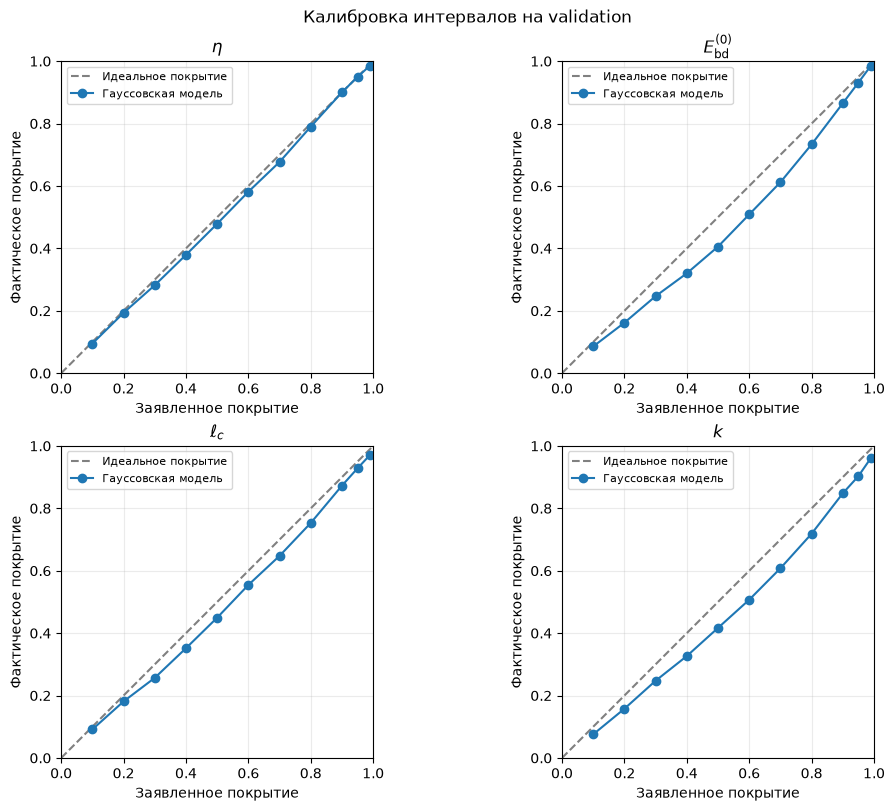

In [13]:
from statistics import NormalDist
import matplotlib.pyplot as plt

nominal_levels = np.array(
    [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]
)

standard_normal = NormalDist()

critical_values = np.array(
    [
        standard_normal.inv_cdf((1.0 + level) / 2.0)
        for level in nominal_levels
    ]
)

standardized_errors = (
    np.abs(validation_true - validation_mean) / validation_sigma
)

calibration_rows = []

for index, target in enumerate(TARGET_COLUMNS):
    for level, critical_value in zip(nominal_levels, critical_values):
        empirical_coverage = np.mean(
            standardized_errors[:, index] <= critical_value
        )

        calibration_rows.append(
            {
                "target": target,
                "nominal_coverage": level,
                "empirical_coverage": empirical_coverage,
            }
        )

validation_calibration = pd.DataFrame(calibration_rows)

validation_calibration.to_csv(
    RESULTS_DIR / "validation_calibration.csv",
    index=False,
)

parameter_labels = {
    "eta": r"$\eta$",
    "mean_breakdown_field": r"$E_{\mathrm{bd}}^{(0)}$",
    "correlation_length": r"$\ell_c$",
    "weibull_shape": r"$k$",
}

with plt.style.context("default"):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(10, 8),
        facecolor="white",
        constrained_layout=True,
    )

    for ax, target in zip(axes.flat, TARGET_COLUMNS):
        target_calibration = validation_calibration.loc[
            validation_calibration["target"] == target
        ]

        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="gray",
            label="Идеальное покрытие",
        )

        ax.plot(
            target_calibration["nominal_coverage"],
            target_calibration["empirical_coverage"],
            marker="o",
            color="tab:blue",
            label="Гауссовская модель",
        )

        ax.set_title(parameter_labels[target])
        ax.set_xlabel("Заявленное покрытие")
        ax.set_ylabel("Фактическое покрытие")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

    fig.suptitle("Калибровка интервалов на validation")

    fig.savefig(
        RESULTS_DIR / "validation_calibration.png",
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

## Результаты гауссовской вероятностной инверсии

### Постановка задачи

По бинарной маске канала пробоя восстанавливаются четыре параметра:
$\eta$, $E_{\mathrm{bd}}^{(0)}$, $\ell_c$ и $k$.

Вместо одного значения для каждого параметра модель предсказывает
среднее $\mu_j(x)$ и дисперсию $\sigma_j^2(x)$:

$$
q(\boldsymbol{\theta}\mid x)
=
\prod_{j=1}^{4}
\mathcal{N}\left(
\theta_j;\mu_j(x),\sigma_j^2(x)
\right).
$$

Среднее задаёт точечное предсказание, а стандартное отклонение —
масштаб предсказанной неопределённости для конкретной маски.

Используется диагональное гауссовское приближение: модель не описывает
условные корреляции между параметрами и несколько раздельных
областей возможных решений.

### Реализованная модель и обучение

Предобученный CNN преобразует маску размером $128\times128$
в вектор из 128 признаков. Его веса заморожены; извлечённые признаки
используются для обучения новой гауссовской головы.

Голова содержит общий слой `128 → 64` с ReLU и две выходные ветви:

- `64 → 4` для средних;
- `64 → 4` для дисперсий, с преобразованием Softplus
  и добавлением положительного минимума.

Обучается 8776 параметров. Функция потерь — отрицательный
логарифм гауссовской плотности (Gaussian NLL), суммированный
по четырём параметрам и усреднённый по объектам.

NLL учитывает одновременно ошибку среднего и величину дисперсии.
Поэтому модель должна балансировать между узкими интервалами
и достаточным покрытием истинных значений.

Обучение выполнено на 6560 масках, validation содержит 1706 масок.
Разбиение проведено по `point_id`, чтобы реализации одной
параметрической точки не попадали в разные части выборки.
Нормализация параметров использует статистики train.

Лучший validation NLL составил **3.9655 на эпохе 6**.
После ранней остановки восстановлены веса этой эпохи.
Это значение рассчитано в нормализованных координатах
и не сравнивается напрямую с MSE или MAE предыдущих моделей.

### Точность средних и покрытие интервалов

Предсказания переведены обратно в исходные единицы.
Для каждого параметра построен центральный гауссовский интервал:

$$
[\mu_j-1.96\sigma_j,\;\mu_j+1.96\sigma_j].
$$

| Параметр | MAE | RMSE | $R^2$ | Покрытие интервала 95% | Средняя ширина интервала |
|---|---:|---:|---:|---:|---:|
| $\eta$ | 0.2478 | 0.3497 | 0.7842 | 94.96% | 1.1504 |
| $E_{\mathrm{bd}}^{(0)}$ | 0.1337 | 0.1621 | 0.0721 | 93.14% | 0.5760 |
| $\ell_c$ | 2.7572 | 3.6163 | 0.3359 | 92.85% | 11.4995 |
| $k$ | 2.0812 | 2.7213 | 0.5038 | 90.33% | 8.2613 |

Наиболее точно по $R^2$ восстанавливается $\eta$.
Для $k$ качество умеренное, для $\ell_c$ — ниже.
Средние предсказания $E_{\mathrm{bd}}^{(0)}$ лишь немного
превосходят постоянное предсказание среднего validation.

Последний результат согласуется с ранее наблюдавшейся трудностью
восстановления порога пробоя по конечной маске. Однако сами метрики
не доказывают фундаментальную неидентифицируемость параметра:
на результат также влияют признаки CNN, обучение и состав данных.

Ширины интервалов выражены в разных физических единицах,
поэтому напрямую сравнивать их между параметрами нельзя.

### Калибровка неопределённости

Калибровочные кривые сравнивают заявленное покрытие интервала
с фактической долей попаданий истинных значений.

Диагональ соответствует совпадению этих величин.
Кривая ниже диагонали означает недостаточное покрытие:
модель заявляет большую уверенность, чем подтверждается данными.

Для $\eta$ кривая близка к диагонали, а покрытие интервала 95%
почти совпадает с номинальным уровнем.

Для $E_{\mathrm{bd}}^{(0)}$, $\ell_c$ и $k$ наблюдается
недостаточное покрытие на большинстве проверенных уровней.
Особенно заметны отклонения для порога пробоя и параметра $k$.
Для $k$ заявленный интервал 95% фактически покрывает около 90%
значений.

Причиной могут быть заниженные дисперсии, ошибки средних
и несоответствие условного распределения гауссовскому приближению.
Одного увеличения дисперсий может быть недостаточно,
чтобы исправить форму всей калибровочной кривой.


In [14]:
-train_evaluation_loader = DataLoader(
    TensorDataset(train_embeddings, train_targets),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

train_mean_normalized, _ = predict_gaussian(
    gaussian_head,
    train_evaluation_loader,
)

train_true_normalized = train_targets.numpy()

train_squared_errors = (
    train_true_normalized - train_mean_normalized
) ** 2

constant_variance_normalized = np.maximum(
    train_squared_errors.mean(axis=0),
    gaussian_head.variance_floor,
)

np.save(
    RESULTS_DIR / "constant_variance_normalized.npy",
    constant_variance_normalized,
)

validation_true_normalized = validation_targets.numpy()

validation_squared_errors = (
    validation_true_normalized - validation_mean_normalized
) ** 2

variance_options = {
    "Индивидуальная дисперсия": validation_variance_normalized,
    "Постоянная дисперсия": np.broadcast_to(
        constant_variance_normalized,
        validation_variance_normalized.shape,
    ),
}

uncertainty_comparison_rows = []
joint_validation_nll = {}

for model_name, variances in variance_options.items():
    nll_per_object_and_target = 0.5 * (
        np.log(2.0 * np.pi)
        + np.log(variances)
        + validation_squared_errors / variances
    )

    joint_validation_nll[model_name] = (
        nll_per_object_and_target.sum(axis=1).mean()
    )

    sigma_original = np.sqrt(variances) * target_scale

    lower95 = validation_mean - 1.96 * sigma_original
    upper95 = validation_mean + 1.96 * sigma_original

    covered95 = (
        (validation_true >= lower95)
        & (validation_true <= upper95)
    )

    for index, target in enumerate(TARGET_COLUMNS):
        uncertainty_comparison_rows.append(
            {
                "model": model_name,
                "target": target,
                "nll": nll_per_object_and_target[:, index].mean(),
                "coverage95": covered95[:, index].mean(),
                "mean_width95": (
                    upper95[:, index] - lower95[:, index]
                ).mean(),
            }
        )

uncertainty_comparison = pd.DataFrame(
    uncertainty_comparison_rows
)

uncertainty_comparison.to_csv(
    RESULTS_DIR / "validation_uncertainty_comparison.csv",
    index=False,
)

display(uncertainty_comparison.round(4))

for model_name, nll in joint_validation_nll.items():
    print(f"{model_name}: validation NLL = {nll:.4f}")

,model,target,nll,coverage95,mean_width95
0,Индивидуальная дисперсия,eta,0.4282,0.9496,1.1504
1,Индивидуальная дисперсия,mean_breakdown_field,1.3995,0.9314,0.5760
2,Индивидуальная дисперсия,correlation_length,1.1015,0.9285,11.4995
3,Индивидуальная дисперсия,weibull_shape,1.0363,0.9033,8.2613
4,Постоянная дисперсия,eta,0.6946,0.9138,1.2064
5,Постоянная дисперсия,mean_breakdown_field,1.3930,0.9343,0.5801
6,Постоянная дисперсия,correlation_length,1.2468,0.8869,12.0439
7,Постоянная дисперсия,weibull_shape,1.1286,0.8734,8.6730


Индивидуальная дисперсия: validation NLL = 3.9655
Постоянная дисперсия: validation NLL = 4.4631


## Сравнение индивидуальной и постоянной дисперсии
Постоянная дисперсия рассчитана по ошибкам на train:

$$
v_j^{\mathrm{const}}
=
\frac{1}{N_{\mathrm{train}}}
\sum_i
(\theta_{ij}-\mu_j(x_i))^2.
$$

Это дисперсия, минимизирующая Gaussian NLL на train
при фиксированных средних. Сравнение выполнено на validation.

### Gaussian NLL

NLL вычисляется в нормализованных координатах.
Меньшее значение соответствует лучшему результату.

| Параметр | Индивидуальная дисперсия | Постоянная дисперсия |
|---|---:|---:|
| $\eta$ | **0.4282** | 0.6946 |
| $E_{\mathrm{bd}}^{(0)}$ | 1.3995 | **1.3930** |
| $\ell_c$ | **1.1015** | 1.2468 |
| $k$ | **1.0363** | 1.1286 |
| **Суммарная NLL** | **3.9655** | **4.4631** |

Индивидуальная дисперсия уменьшает суммарную validation NLL
на **0.4976**. Наибольший вклад в улучшение даёт $\eta$.
Для $\ell_c$ и $k$ также получен выигрыш.

Для $E_{\mathrm{bd}}^{(0)}$ индивидуальная дисперсия
не даёт улучшения: постоянный вариант имеет немного меньшую NLL.

### Покрытие и ширина интервалов 95%

| Параметр | Покрытие: индивидуальная | Покрытие: постоянная | Ширина: индивидуальная | Ширина: постоянная |
|---|---:|---:|---:|---:|
| $\eta$ | 94.96% | 91.38% | 1.1504 | 1.2064 |
| $E_{\mathrm{bd}}^{(0)}$ | 93.14% | 94.33% | 0.5760 | 0.5801 |
| $\ell_c$ | 92.85% | 88.69% | 11.4995 | 12.0439 |
| $k$ | 90.33% | 87.34% | 8.2613 | 8.6730 |

Для $\eta$, $\ell_c$ и $k$ индивидуальные интервалы имеют
большее покрытие при меньшей средней ширине.

Такой результат согласуется с более удачным распределением
ширины интервалов между объектами: модель может задавать
разный масштаб неопределённости для разных масок.
При этом средняя ширина не означает, что индивидуальный
интервал уже постоянного для каждого отдельного объекта.

Для $E_{\mathrm{bd}}^{(0)}$ постоянный вариант имеет
покрытие ближе к номинальным 95% и немного большую ширину.

In [15]:
validation_squared_errors = (
    validation_targets.numpy().astype(np.float64)
    - validation_mean_normalized
) ** 2

variance_scale = np.maximum(
    (
        validation_squared_errors
        / validation_variance_normalized
    ).mean(axis=0),
    1e-12,
)

sigma_scale = np.sqrt(variance_scale)

validation_variance_calibrated_normalized = (
    validation_variance_normalized * variance_scale
)

validation_sigma_calibrated = (
    validation_sigma * sigma_scale
)

validation_lower95_calibrated = (
    validation_mean - 1.96 * validation_sigma_calibrated
)

validation_upper95_calibrated = (
    validation_mean + 1.96 * validation_sigma_calibrated
)

coverage_before = (
    (validation_true >= validation_lower95)
    & (validation_true <= validation_upper95)
).mean(axis=0)

coverage_after = (
    (validation_true >= validation_lower95_calibrated)
    & (validation_true <= validation_upper95_calibrated)
).mean(axis=0)

nll_before = 0.5 * (
    np.log(2.0 * np.pi)
    + np.log(validation_variance_normalized)
    + validation_squared_errors / validation_variance_normalized
)

nll_after = 0.5 * (
    np.log(2.0 * np.pi)
    + np.log(validation_variance_calibrated_normalized)
    + validation_squared_errors
    / validation_variance_calibrated_normalized
)

calibration_summary = pd.DataFrame(
    {
        "target": TARGET_COLUMNS,
        "sigma_multiplier": sigma_scale,
        "coverage95_before": coverage_before,
        "coverage95_after": coverage_after,
        "nll_before": nll_before.mean(axis=0),
        "nll_after": nll_after.mean(axis=0),
    }
)

calibration_summary.to_csv(
    RESULTS_DIR / "validation_scale_calibration.csv",
    index=False,
)

constant_variance_scale = np.maximum(
    (
        validation_squared_errors
        / constant_variance_normalized
    ).mean(axis=0),
    1e-12,
)

constant_sigma_scale = np.sqrt(constant_variance_scale)

calibrated_checkpoint = dict(best_gaussian_checkpoint)

calibrated_checkpoint["calibration"] = {
    "method": "gaussian_nll_scale",
    "fit_split": "validation",
    "sigma_scale": sigma_scale.tolist(),
    "constant_variance_normalized": (
        constant_variance_normalized.tolist()
    ),
    "constant_sigma_scale": constant_sigma_scale.tolist(),
}

CALIBRATED_MODEL_FILE = (
    RESULTS_DIR / "best_gaussian_inverse_calibrated.pt"
)

torch.save(
    calibrated_checkpoint,
    CALIBRATED_MODEL_FILE,
)

display(calibration_summary.round(4))

print(
    "Validation NLL до калибровки:",
    round(float(nll_before.sum(axis=1).mean()), 4),
)

print(
    "Validation NLL после калибровки:",
    round(float(nll_after.sum(axis=1).mean()), 4),
)

print("Модель с коэффициентами калибровки:", CALIBRATED_MODEL_FILE)

,target,sigma_multiplier,coverage95_before,coverage95_after,nll_before,nll_after
0,eta,1.0359,0.9496,0.9572,0.4282,0.4269
1,mean_breakdown_field,1.1117,0.9314,0.9584,1.3995,1.3874
2,correlation_length,1.1620,0.9285,0.9566,1.1015,1.0765
3,weibull_shape,1.2483,0.9033,0.9543,1.0363,0.9790


Validation NLL до калибровки: 3.9655
Validation NLL после калибровки: 3.8698
Модель с коэффициентами калибровки: /home/artur/PycharmProjects/Mathprac/results/probabilistic_inverse/best_gaussian_inverse_calibrated.pt


In [16]:
test_mean_normalized, test_variance_normalized = predict_gaussian(
    gaussian_head,
    test_loader,
)

test_true_normalized = test_targets.numpy().astype(np.float64)

test_mean = (
    test_mean_normalized * target_scale + target_location
)

test_true = test_data[TARGET_COLUMNS].to_numpy(
    dtype=np.float64
)

assert (
    test_mean.shape
    == test_variance_normalized.shape
    == test_true.shape
)

test_squared_errors = (
    test_true_normalized - test_mean_normalized
) ** 2

# Используем уже зафиксированные коэффициенты из чекпоинта.
calibration = calibrated_checkpoint["calibration"]

fixed_sigma_scale = np.asarray(
    calibration["sigma_scale"],
    dtype=np.float64,
)

fixed_constant_variance = np.asarray(
    calibration["constant_variance_normalized"],
    dtype=np.float64,
)

fixed_constant_sigma_scale = np.asarray(
    calibration["constant_sigma_scale"],
    dtype=np.float64,
)

test_variance_options = {
    "Gaussian": test_variance_normalized,
    "Gaussian calibrated": (
        test_variance_normalized * fixed_sigma_scale ** 2
    ),
    "Constant": np.broadcast_to(
        fixed_constant_variance,
        test_variance_normalized.shape,
    ),
    "Constant calibrated": np.broadcast_to(
        fixed_constant_variance * fixed_constant_sigma_scale ** 2,
        test_variance_normalized.shape,
    ),
}

point_metric_rows = []

for index, target in enumerate(TARGET_COLUMNS):
    actual = test_true[:, index]
    predicted = test_mean[:, index]

    point_metric_rows.append(
        {
            "target": target,
            "mae": mean_absolute_error(actual, predicted),
            "rmse": np.sqrt(np.mean((actual - predicted) ** 2)),
            "r2": r2_score(actual, predicted),
        }
    )

test_point_metrics = pd.DataFrame(point_metric_rows)

uncertainty_metric_rows = []
joint_nll_rows = []

for model_name, variances in test_variance_options.items():
    nll = 0.5 * (
        np.log(2.0 * np.pi)
        + np.log(variances)
        + test_squared_errors / variances
    )

    sigma_original = np.sqrt(variances) * target_scale

    lower95 = test_mean - 1.96 * sigma_original
    upper95 = test_mean + 1.96 * sigma_original

    covered95 = (
        (test_true >= lower95)
        & (test_true <= upper95)
    )

    joint_nll_rows.append(
        {
            "model": model_name,
            "test_nll": nll.sum(axis=1).mean(),
        }
    )

    for index, target in enumerate(TARGET_COLUMNS):
        uncertainty_metric_rows.append(
            {
                "model": model_name,
                "target": target,
                "nll": nll[:, index].mean(),
                "coverage95": covered95[:, index].mean(),
                "mean_width95": (
                    upper95[:, index] - lower95[:, index]
                ).mean(),
            }
        )

test_uncertainty_metrics = pd.DataFrame(
    uncertainty_metric_rows
)

test_joint_nll = pd.DataFrame(joint_nll_rows)

test_sigma = (
    np.sqrt(test_variance_normalized) * target_scale
)

test_sigma_calibrated = test_sigma * fixed_sigma_scale

test_predictions = test_data[
    ["run_id", "point_id"]
].reset_index(drop=True).copy()

for index, target in enumerate(TARGET_COLUMNS):
    test_predictions[f"true_{target}"] = test_true[:, index]
    test_predictions[f"predicted_{target}"] = test_mean[:, index]
    test_predictions[f"sigma_{target}"] = test_sigma[:, index]

    test_predictions[f"sigma_calibrated_{target}"] = (
        test_sigma_calibrated[:, index]
    )

    test_predictions[f"lower95_calibrated_{target}"] = (
        test_mean[:, index] - 1.96 * test_sigma_calibrated[:, index]
    )

    test_predictions[f"upper95_calibrated_{target}"] = (
        test_mean[:, index] + 1.96 * test_sigma_calibrated[:, index]
    )

test_point_metrics.to_csv(
    RESULTS_DIR / "test_point_metrics.csv",
    index=False,
)

test_uncertainty_metrics.to_csv(
    RESULTS_DIR / "test_uncertainty_metrics.csv",
    index=False,
)

test_joint_nll.to_csv(
    RESULTS_DIR / "test_joint_nll.csv",
    index=False,
)

test_predictions.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False,
)

print("Точность средних предсказаний:")
display(test_point_metrics.round(4))

print("Суммарная Gaussian NLL:")
display(test_joint_nll.round(4))

print("Покрытие и ширина интервалов:")
display(test_uncertainty_metrics.round(4))

Точность средних предсказаний:


,target,mae,rmse,r2
0,eta,0.2160,0.2942,0.8337
1,mean_breakdown_field,0.1335,0.1602,0.0687
2,correlation_length,3.1952,4.0984,0.1540
3,weibull_shape,2.2581,2.8682,0.4241


Суммарная Gaussian NLL:


,model,test_nll
0,Gaussian,4.2875
1,Gaussian calibrated,4.1336
2,Constant,4.5411
3,Constant calibrated,4.3970


Покрытие и ширина интервалов:


,model,target,nll,coverage95,mean_width95
0,Gaussian,eta,0.3616,0.9426,1.0503
1,Gaussian,mean_breakdown_field,1.3783,0.9369,0.5677
2,Gaussian,correlation_length,1.3745,0.8857,12.5460
3,Gaussian,weibull_shape,1.1731,0.8976,8.8308
4,Gaussian calibrated,eta,0.3606,0.9519,1.0880
5,Gaussian calibrated,mean_breakdown_field,1.3675,0.9648,0.6311
6,Gaussian calibrated,correlation_length,1.3091,0.9250,14.5789
7,Gaussian calibrated,weibull_shape,1.0963,0.9488,11.0233
8,Constant,eta,0.5059,0.9477,1.2064
9,Constant,mean_breakdown_field,1.3789,0.9410,0.5801


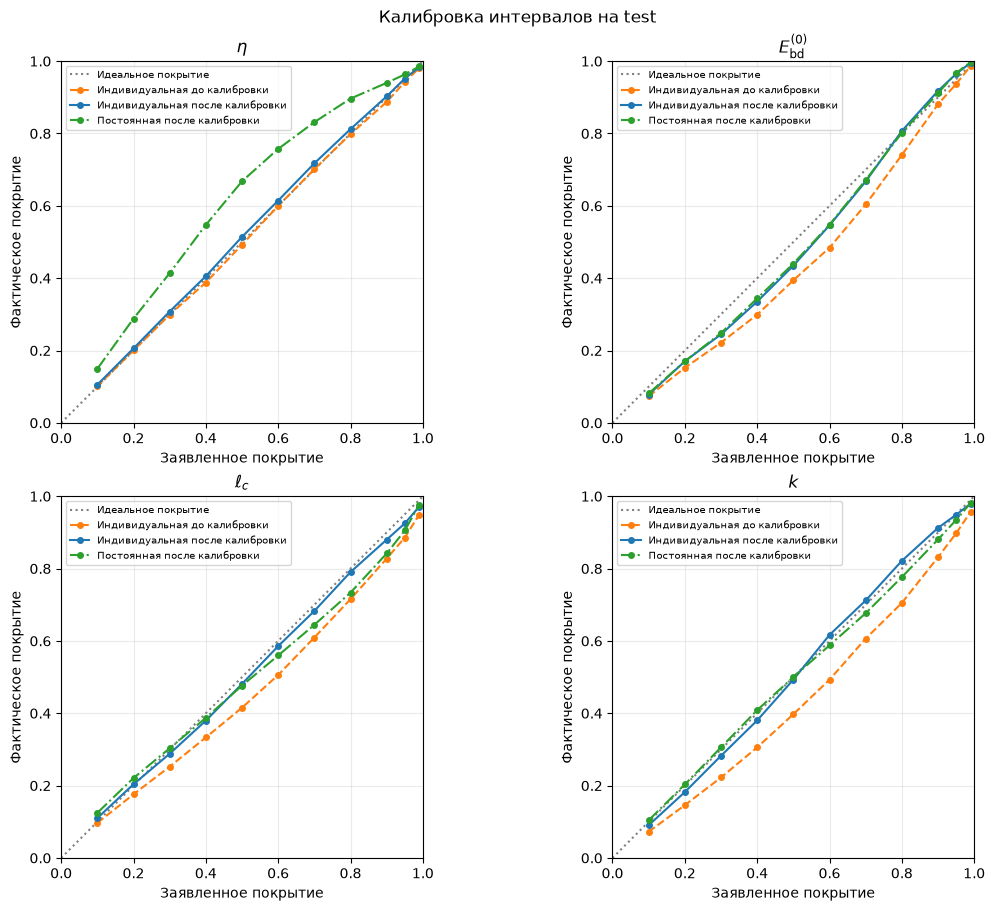

In [17]:
test_calibration_rows = []

test_absolute_errors_normalized = np.abs(
    test_true_normalized - test_mean_normalized
)

for model_name, variances in test_variance_options.items():
    standardized_errors = (
        test_absolute_errors_normalized / np.sqrt(variances)
    )

    for index, target in enumerate(TARGET_COLUMNS):
        for level, critical_value in zip(
            nominal_levels,
            critical_values,
        ):
            empirical_coverage = np.mean(
                standardized_errors[:, index] <= critical_value
            )

            test_calibration_rows.append(
                {
                    "model": model_name,
                    "target": target,
                    "nominal_coverage": level,
                    "empirical_coverage": empirical_coverage,
                }
            )

test_calibration = pd.DataFrame(test_calibration_rows)

test_calibration.to_csv(
    RESULTS_DIR / "test_calibration.csv",
    index=False,
)

plot_styles = {
    "Gaussian": {
        "label": "Индивидуальная до калибровки",
        "color": "tab:orange",
        "linestyle": "--",
    },
    "Gaussian calibrated": {
        "label": "Индивидуальная после калибровки",
        "color": "tab:blue",
        "linestyle": "-",
    },
    "Constant calibrated": {
        "label": "Постоянная после калибровки",
        "color": "tab:green",
        "linestyle": "-.",
    },
}

with plt.style.context("default"):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11, 9),
        facecolor="white",
        constrained_layout=True,
    )

    for ax, target in zip(axes.flat, TARGET_COLUMNS):
        ax.plot(
            [0, 1],
            [0, 1],
            color="gray",
            linestyle=":",
            label="Идеальное покрытие",
        )

        for model_name, style in plot_styles.items():
            selected = test_calibration.loc[
                (test_calibration["target"] == target)
                & (test_calibration["model"] == model_name)
            ]

            ax.plot(
                selected["nominal_coverage"],
                selected["empirical_coverage"],
                marker="o",
                markersize=4,
                **style,
            )

        ax.set_title(parameter_labels[target])
        ax.set_xlabel("Заявленное покрытие")
        ax.set_ylabel("Фактическое покрытие")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=7, loc="upper left")

    fig.suptitle("Калибровка интервалов на test")

    fig.savefig(
        RESULTS_DIR / "test_calibration.png",
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

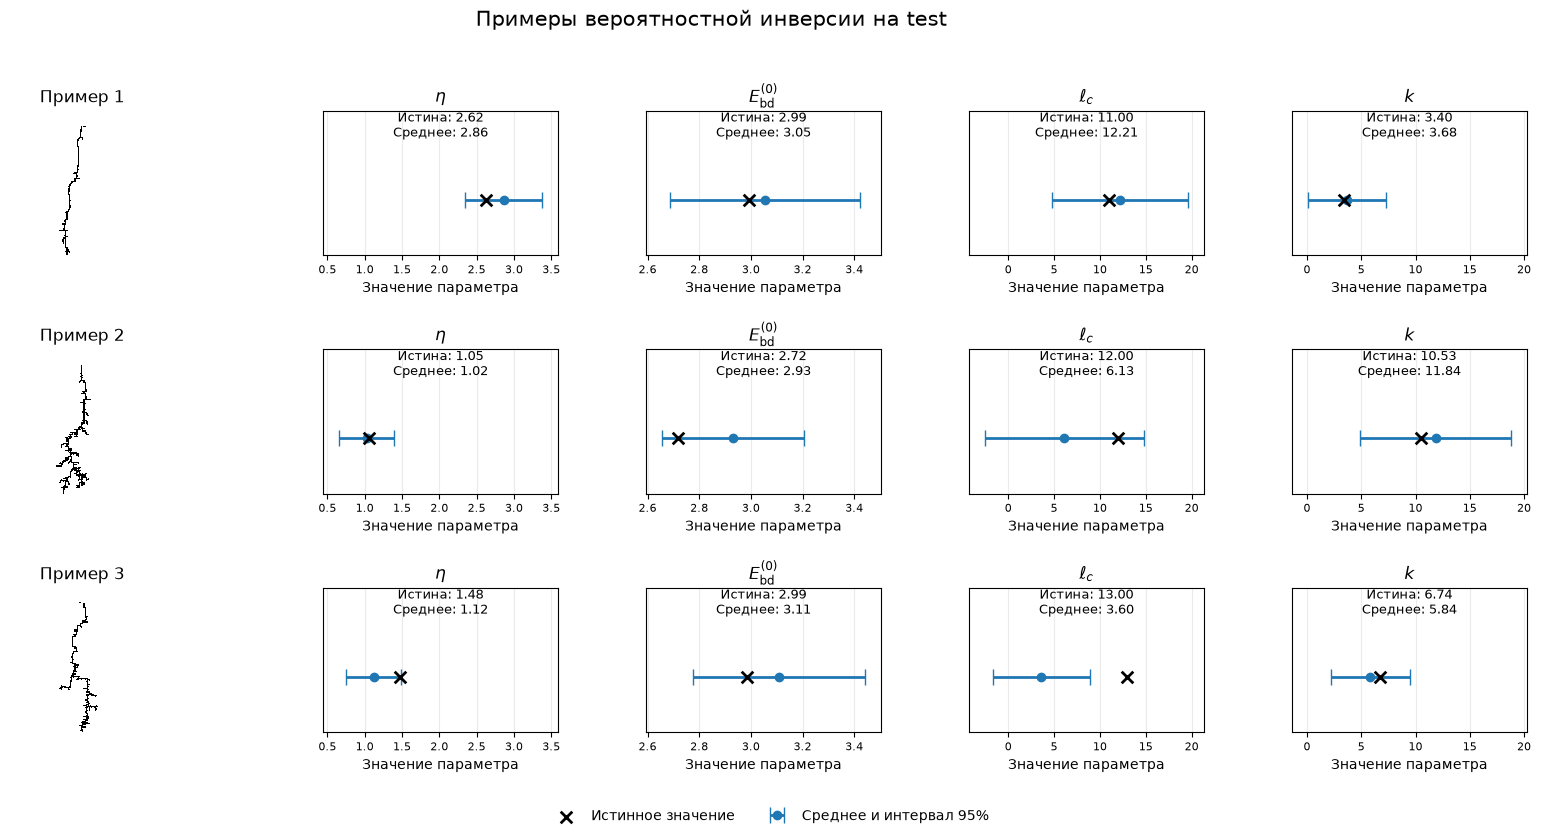

,example,run_id,point_id,target,true,predicted,sigma_calibrated,lower95,upper95,covered95
0,1,test-001342-m1-g0,test-001342,eta,2.6246,2.8629,0.2622,2.3491,3.3768,True
1,1,test-001342-m1-g0,test-001342,mean_breakdown_field,2.9931,3.0545,0.1870,2.6880,3.4209,True
2,1,test-001342-m1-g0,test-001342,correlation_length,11.0000,12.2072,3.7698,4.8183,19.5962,True
3,1,test-001342-m1-g0,test-001342,weibull_shape,3.3993,3.6834,1.8384,0.0802,7.2865,True
4,2,test-000184-m0-g0,test-000184,eta,1.0506,1.0245,0.1883,0.6555,1.3935,True
5,2,test-000184-m0-g0,test-000184,mean_breakdown_field,2.7177,2.9314,0.1407,2.6557,3.2071,True
6,2,test-000184-m0-g0,test-000184,correlation_length,12.0000,6.1280,4.4253,-2.5455,14.8015,True
7,2,test-000184-m0-g0,test-000184,weibull_shape,10.5334,11.8446,3.5435,4.8993,18.7899,True
8,3,test-001580-m0-g0,test-001580,eta,1.4782,1.1193,0.1898,0.7474,1.4913,True
9,3,test-001580-m0-g0,test-001580,mean_breakdown_field,2.9851,3.1091,0.1698,2.7763,3.4419,True


In [18]:
example_rng = np.random.default_rng(SEED)

candidate_indices = (
    test_data.reset_index(drop=True)
    .drop_duplicates(subset="point_id")
    .index.to_numpy()
)

number_of_examples = min(3, len(candidate_indices))

example_indices = example_rng.choice(
    candidate_indices,
    size=number_of_examples,
    replace=False,
)

example_means = test_mean[example_indices]
example_true = test_true[example_indices]
example_sigmas = test_sigma_calibrated[example_indices]

example_lower95 = example_means - 1.96 * example_sigmas
example_upper95 = example_means + 1.96 * example_sigmas

axis_minimum = np.minimum(
    example_lower95,
    example_true,
).min(axis=0)

axis_maximum = np.maximum(
    example_upper95,
    example_true,
).max(axis=0)

axis_padding = 0.08 * np.maximum(
    axis_maximum - axis_minimum,
    1e-6,
)

example_rows = []

with plt.style.context("default"):
    fig, axes = plt.subplots(
        number_of_examples,
        5,
        figsize=(17, 2.8 * number_of_examples),
        squeeze=False,
        facecolor="white",
        gridspec_kw={
            "width_ratios": [1.3, 1, 1, 1, 1],
        },
    )

    for row, sample_index in enumerate(example_indices):
        sample = test_data.iloc[sample_index]

        with np.load(
            DATA_DIR / sample["image_path"],
            allow_pickle=False,
        ) as saved:
            mask = saved["channel"]

        mask_ax = axes[row, 0]

        mask_ax.imshow(
            mask,
            cmap="gray_r",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )

        mask_ax.set_title(f"Пример {row + 1}")
        mask_ax.axis("off")

        for index, target in enumerate(TARGET_COLUMNS):
            ax = axes[row, index + 1]

            mean = example_means[row, index]
            actual = example_true[row, index]
            half_width = 1.96 * example_sigmas[row, index]

            ax.errorbar(
                mean,
                0,
                xerr=half_width,
                fmt="o",
                color="tab:blue",
                capsize=6,
                linewidth=2,
                label="Среднее и интервал 95%",
            )

            ax.scatter(
                actual,
                0,
                marker="x",
                color="black",
                s=70,
                linewidths=2,
                zorder=5,
                label="Истинное значение",
            )

            ax.text(
                0.5,
                0.82,
                f"Истина: {actual:.2f}\nСреднее: {mean:.2f}",
                transform=ax.transAxes,
                ha="center",
                fontsize=9,
            )

            ax.set_title(parameter_labels[target])
            ax.set_xlim(
                axis_minimum[index] - axis_padding[index],
                axis_maximum[index] + axis_padding[index],
            )
            ax.set_ylim(-0.5, 0.8)
            ax.set_yticks([])
            ax.set_xlabel("Значение параметра")
            ax.tick_params(axis="x", labelsize=8)
            ax.grid(axis="x", alpha=0.25)

            lower = example_lower95[row, index]
            upper = example_upper95[row, index]

            example_rows.append(
                {
                    "example": row + 1,
                    "run_id": sample["run_id"],
                    "point_id": sample["point_id"],
                    "target": target,
                    "true": actual,
                    "predicted": mean,
                    "sigma_calibrated": example_sigmas[row, index],
                    "lower95": lower,
                    "upper95": upper,
                    "covered95": bool(lower <= actual <= upper),
                }
            )

    handles, labels = axes[0, 1].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=2,
        frameon=False,
    )

    fig.suptitle(
        "Примеры вероятностной инверсии на test",
        fontsize=15,
        y=0.98,
    )

    fig.subplots_adjust(
        left=0.04,
        right=0.98,
        bottom=0.12,
        top=0.86,
        hspace=0.65,
        wspace=0.35,
    )

    fig.savefig(
        RESULTS_DIR / "test_inverse_examples.png",
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

example_predictions = pd.DataFrame(example_rows)

example_predictions.to_csv(
    RESULTS_DIR / "test_inverse_examples.csv",
    index=False,
)

display(example_predictions.round(4))

## Итоговые выводы: гауссовская вероятностная инверсия

### Реализованный подход

По бинарной маске канала пробоя модель предсказывает средние
и дисперсии четырёх параметров:
$\eta$, $E_{\mathrm{bd}}^{(0)}$, $\ell_c$ и $k$.

Использован замороженный предобученный CNN и гауссовская голова
с 8776 обучаемыми параметрами. Голова обучена по Gaussian NLL.
Для каждого параметра задаётся отдельное нормальное распределение;
ковариации между параметрами не моделируются.

Обучение проведено на 6560 объектах, выбор эпохи и калибровка —
на 1706 объектах validation. Окончательная оценка выполнена
на 1933 объектах test. Разбиение по `point_id` исключает попадание
реализаций одной параметрической точки в разные части выборки.

### Результаты на test

Покрытие и ширина приведены для откалиброванных индивидуальных
интервалов с заявленным уровнем 95%.

| Параметр | MAE | RMSE | $R^2$ | Покрытие 95% | Средняя ширина |
|---|---:|---:|---:|---:|---:|
| $\eta$ | 0.2160 | 0.2942 | 0.8337 | 95.19% | 1.0880 |
| $E_{\mathrm{bd}}^{(0)}$ | 0.1335 | 0.1602 | 0.0687 | 96.48% | 0.6311 |
| $\ell_c$ | 3.1952 | 4.0984 | 0.1540 | 92.50% | 14.5789 |
| $k$ | 2.2581 | 2.8682 | 0.4241 | 94.88% | 11.0233 |

Наиболее точно восстанавливается $\eta$. Для $k$ качество умеренное.
Восстановление $\ell_c$ остаётся трудным, а предсказания
$E_{\mathrm{bd}}^{(0)}$ лишь немного превосходят постоянное
предсказание среднего test.

Эти результаты характеризуют текущую модель и выборку.
Они сами по себе не доказывают фундаментальную
неидентифицируемость параметров.

### Польза индивидуальной дисперсии

Сравнение выполнено при одинаковых средних предсказаниях.
Меняется только способ оценки неопределённости.

| Вариант | Test NLL ↓ |
|---|---:|
| Индивидуальная дисперсия | 4.2875 |
| Индивидуальная после калибровки | **4.1336** |
| Постоянная дисперсия | 4.5411 |
| Постоянная после калибровки | 4.3970 |

Индивидуальная дисперсия показывает меньшую NLL
как до, так и после калибровки. После одинаковой процедуры
настройки на validation преимущество перед постоянным вариантом
составляет **0.2634 по суммарной test NLL**.

Таким образом, зависимость предсказанной дисперсии от маски
даёт наблюдаемый выигрыш на отложенных данных.
Статистическая значимость этого различия не оценивалась.

NLL рассчитана в нормализованных координатах с суммированием
по четырём параметрам и усреднением по объектам.

### Калибровка интервалов

Подобранные на validation множители сигмы улучшили результат
на test: NLL снизилась с **4.2875 до 4.1336**.

Покрытие интервалов изменилось:

- $\eta$: 94.26% → **95.19%**;
- $E_{\mathrm{bd}}^{(0)}$: 93.69% → **96.48%**;
- $\ell_c$: 88.57% → **92.50%**;
- $k$: 89.76% → **94.88%**.

Для $\eta$ и $k$ покрытие близко к номинальному.
Для $\ell_c$ недостаточное покрытие сохранилось.
Калибровочные кривые также показывают, что одной поправки
масштаба недостаточно для точного согласования всех уровней.

Увеличение покрытия сопровождается расширением интервалов.
Поэтому покрытие следует оценивать вместе с их шириной
и практической информативностью.

### Примеры и ограничения

Примеры показывают, что истинное значение может попадать
в широкий интервал даже при большой ошибке среднего.
Во втором примере для $\ell_c$ истина равна 12,
а среднее предсказание — примерно 6.13; интервал покрывает истину.

В третьем примере для $\ell_c$ истина равна 13,
а предсказание — примерно 3.60. Интервал
$[-1.69;\,8.88]$ не покрывает истинное значение.
Это иллюстрирует сохраняющиеся ошибки вероятностной инверсии.

Отрицательные границы интервалов для положительного параметра
показывают ограничение обычного гауссовского приближения:
оно не учитывает физические границы области параметров.

Кроме того:

- диагональное распределение не описывает корреляции
  и несколько раздельных областей возможных решений;
- предсказанная дисперсия может учитывать ошибки среднего
  и не является отдельной оценкой неопределённости весов сети;
- среднее покрытие по выборке не гарантирует правильных
  интервалов для каждой маски;
- четыре отдельных интервала 95% не обеспечивают автоматически
  совместное покрытие 95%;
- результаты относятся к распределению синтетических данных DBM;
  перенос на реальные изображения не проверен.

### Итог

Вероятностная инверсия реализована и проверена на test.
Индивидуальная оценка дисперсии улучшает Gaussian NLL
относительно постоянного baseline, а калибровка на validation
улучшает покрытие на отложенных данных.

Полученная модель позволяет выдавать точечные предсказания
вместе с интервалами неопределённости. При этом высокая точность
достигнута прежде всего для $\eta$, а восстановление
$E_{\mathrm{bd}}^{(0)}$ и $\ell_c$ остаётся ограниченным.

Сохранены веса модели, статистики нормализации,
коэффициенты калибровки, test-предсказания, метрики
и диагностические графики. Этап гауссовской инверсии завершён.